# 🌱 Sistema experto de selección de cultivos para huertas urbanas (AMBA)



**Análisis de Datos II · 2026.2**
* Grupo proveedor **E**
* Grupo cliente **F**
Catálogo `cultivos_v6.csv` (16 especies)
* Motor **Experta** (encadenamiento hacia adelante)

Este notebook es la **demo ejecutable** para realizar pruebas 22/10

| Qué muestra | Requisitos del brief |
|---|---|
| Ingreso de las condiciones de la huerta (luz, espacio, recipiente, mes, riego) | RF-01 a RF-06 |
| Lista de cultivos recomendados con **explicación** y **pautas mínimas de cuidado** | RF-07, RF-08 |
| Mensaje claro cuando **no hay** cultivos adecuados | RF-09 |
| **Motivos de descarte** de los demás cultivos | RF-10 |
| Trazabilidad: qué regla (R1.1 … R5.7) y qué fuente respaldan cada conclusión | Fuentes de conocimiento |

> ⚠️ **Aviso (siempre visible en la UI):** esta herramienta orienta la elección de cultivos: no garantiza que un cultivo crezca, no diagnostica enfermedades ni reemplaza el consejo de un especialista.



### Arquitectura en tres capas desacopladas
| Capa | Qué vive ahí |
|---|---|
| **UI / textos** | frases de riego, etiquetas de luz, plantillas de mensajes, aviso fijo |
| **Cargador** | traduce las cadenas del CSV a números y códigos; rechaza lo desconocido |
| **Motor** | sólo números y códigos: las reglas **no contienen texto para el usuario** |

### Encadenamiento (5 niveles)
`Nivel 0` hechos de entrada → `Nivel 1` categorías/estación/ventana de siembra → `Nivel 2` perfil y temporada → `Nivel 3` evaluación numérica (Cumple/Falla) → `Nivel 4` conclusiones (Recomendación/Descarte/SinResultados) → `Nivel 5` enriquecimiento (pautas, sugerencias, advertencias).
25 reglas lógicas = **32 `@Rule`** (las variantes a/b/c/d son reglas separadas para que cada una deje su traza).

## 1. Preparación del entorno
Si falta Experta: `pip install experta`. La versión 1.9.4 **falla al importar en Python ≥ 3.10** por `collections.Mapping`; el parche se aplica **antes** de importar Experta.

In [24]:
!pip install experta

In [25]:
# Ajuste de compatibilidad para Python 3.10 o superior
import collections
import collections.abc
for nombre in ["Mapping", "MutableMapping", "Iterable", "Sequence"]:
    if not hasattr(collections, nombre):
        setattr(collections, nombre, getattr(collections.abc, nombre))

from experta import *
print("Experta listo")

Experta listo
Experta listo


In [26]:
import csv, random, itertools, re
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML


## 2. Capa de textos (UI)
Todo el texto que ve el usuario sale de **esta tabla de plantillas** indexada por código (sección C.6 de la especificación). Las reglas sólo emiten *códigos* y *números*.
`[ ... ]` es un segmento opcional que se omite si falta algún dato.

In [27]:
MESES = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio',
         'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre']

# Opciones de cuidado: la UI muestra la frase y envía el CÓDIGO entero al motor
OPCIONES_CUIDADO = {1: 'Puedo regar 1 vez por semana o menos',
                    2: 'Puedo regar 2 o 3 veces por semana',
                    3: 'Puedo regar de forma diaria o casi diaria'}
FRASE_RIEGO = {1: '1 vez por semana o menos',
               2: '2 o 3 veces por semana',
               3: 'de forma diaria o casi diaria'}

AVISO_FIJO = ("Esta herramienta orienta la elección de cultivos: no garantiza que un cultivo crezca, "
              "no diagnostica enfermedades ni reemplaza el consejo de un especialista.")

def etiqueta_luz(h):
    """Etiqueta DECORATIVA (solo UI). Ninguna regla de descarte la lee."""
    return 'Sombra parcial' if h < 3 else ('Sol moderado' if h <= 5 else 'Sol pleno')

PLANTILLAS = {
    'LUZ_OK':    'Pide al menos {req} h de sol y tenés {usr} h.',
    'LUZ_FALTA': 'Le faltan horas de sol: pide al menos {req} h y tenés {usr} h.',
    'ESP_OK':    'Necesita {req} m² y tenés {usr} m².',
    'ESP_FALTA': 'No alcanza el espacio: necesita {req} m² y tenés {usr} m².',
    'REC_OK':    'Necesita {req} cm de profundidad y tu recipiente tiene {usr} cm.',
    'REC_FALTA': 'El recipiente es poco profundo: necesita {req} cm y el tuyo tiene {usr} cm.',
    'CUI_OK':    'Se riega {req_frase} y vos podés regar {usr_frase}.',
    'CUI_FALTA': 'Se riega {req_frase}, pero vos podés regar {usr_frase}.',
    'DESC_EPOCA': 'Estamos en {mes} y no es su época: se siembra en {meses_siembra}[ y se trasplanta en {meses_trasplante}].',
    'MSG_SIN_RESULTADOS': 'Ningún cultivo del catálogo cumple las condiciones de tu huerta en este mes.',
    'PAU_RIEGO_1': 'Regar una vez por semana.',
    'PAU_RIEGO_2': 'Regar 2 o 3 veces por semana.',
    'PAU_RIEGO_3': 'Regar todos los días o casi todos los días.',
    'PAU_MANT': 'Labores: {p1}. Atención sugerida: {p2}.',
    'PAU_COS':  'Hortaliza de {p3}. Manejo de cosecha: {p1}. Ciclo estimado: {p2} días.',
    'SUG_SIEMBRA_DIRECTA':  'Este mes podés sembrar directo en el recipiente.',
    'SUG_SIEMBRA_ALMACIGO': 'Este mes podés preparar un almácigo con semillas y trasplantar después.',
    'SUG_SIEMBRA_AMBOS':    'Este mes podés sembrar directo en el recipiente o preparar un almácigo con semillas.',
    'SUG_AMBAS_DIRECTA':    'Este mes podés sembrar directo en el recipiente o comprar plantines y trasplantar.',
    'SUG_AMBAS_ALMACIGO':   'Este mes podés preparar un almácigo con semillas o comprar plantines y trasplantar.',
    'SUG_AMBAS_AMBOS':      'Este mes podés sembrar directo, preparar un almácigo con semillas o comprar plantines y trasplantar.',
    'SUG_PLANTINES': ('La época de siembra por semilla ya pasó, pero estás a tiempo de incorporar el cultivo '
                      'comprando plantines para trasplantar este mes.'),
    'SUG_VERANO':    'Es verano: protegé el suelo de la evaporación.',
    'ADV_ALMACIGO':  'Mantené el almácigo protegido del frío.',
    'ADV_HELADA':    'Es sensible a heladas: protegelo en las noches frías.',
}

# C.7 — Sugerencia de inicio: (modo, método de siembra) -> código de plantilla
TABLA_INICIO = {
    ('siembra', 'directa'): 'SUG_SIEMBRA_DIRECTA', ('siembra', 'almacigo'): 'SUG_SIEMBRA_ALMACIGO', ('siembra', 'ambos'): 'SUG_SIEMBRA_AMBOS',
    ('ambas',   'directa'): 'SUG_AMBAS_DIRECTA',   ('ambas',   'almacigo'): 'SUG_AMBAS_ALMACIGO',   ('ambas',   'ambos'): 'SUG_AMBAS_AMBOS',
    ('plantines', 'directa'): 'SUG_PLANTINES', ('plantines', 'almacigo'): 'SUG_PLANTINES', ('plantines', 'ambos'): 'SUG_PLANTINES',
}

def fmt(x):
    return f'{x:g}' if isinstance(x, (int, float)) else str(x)

def nombres_meses(meses):
    meses = sorted(meses)
    if len(meses) == 12: return 'todo el año'
    nombres = [MESES[m - 1] for m in meses]
    if not nombres: return ''
    return nombres[0] if len(nombres) == 1 else ', '.join(nombres[:-1]) + ' y ' + nombres[-1]

def render(codigo, **datos):
    """Rellena una plantilla. Un segmento [ ... ] se omite si le falta algún dato."""
    def opcional(m):
        campos = re.findall(r'{(\w+)}', m.group(1))
        return m.group(1).format(**datos) if all(datos.get(k) for k in campos) else ''
    plantilla = re.sub(r'\[(.*?)\]', opcional, PLANTILLAS[codigo])
    datos = {k: (v.rstrip('. ') if k.startswith('p') and isinstance(v, str) else v) for k, v in datos.items()}
    return plantilla.format(**datos)

def texto_criterio(codigo, usr, req):
    """Texto de un hecho Cumple/Falla/Descarte a partir de su código y sus números."""
    if codigo.startswith('CUI'):
        return render(codigo, req_frase=FRASE_RIEGO[req], usr_frase=FRASE_RIEGO[usr])
    if codigo == 'DESC_EPOCA':
        siembra, trasplante = req
        return render(codigo, mes=MESES[usr - 1], meses_siembra=nombres_meses(siembra),
                      meses_trasplante=nombres_meses(trasplante) if trasplante else None)
    return render(codigo, req=fmt(req), usr=fmt(usr))

print(render('LUZ_OK', req='5', usr='6'))
print(render('DESC_EPOCA', mes='abril', meses_siembra='septiembre', meses_trasplante=None))

Pide al menos 5 h de sol y tenés 6 h.
Estamos en abril y no es su época: se siembra en septiembre.
Pide al menos 5 h de sol y tenés 6 h.
Estamos en abril y no es su época: se siembra en septiembre.


## 3. Cargador del catálogo (`cultivos_v6.csv`)
Traduce **todo a números y códigos** y **rechaza lo desconocido**:
`bajo/moderado/frecuente → 1/2/3`, meses → `frozenset` de 1-12 (`todo_el_año` = los doce), booleanos de estación → conjunto de estaciones, `si/no` → bool.
La vigencia depende **sólo** de `meses_siembra` y `meses_trasplante`; las columnas de estación sólo condicionan consejos de nivel 5.

In [28]:
MAPEO_CSV = {'bajo': 1, 'moderado': 2, 'frecuente': 3}
MESES_NUM = {m: i + 1 for i, m in enumerate(MESES)}
METODOS = {'directa': 'directa', 'almácigo': 'almacigo', 'ambos': 'ambos'}
ESTACIONES = ['verano', 'otoño', 'invierno', 'primavera']

def _meses(txt, campo, cultivo):
    txt = txt.strip()
    if txt in ('', 'no'):
        return frozenset()
    if txt == 'todo_el_año':
        return frozenset(range(1, 13))
    out = set()
    for parte in txt.split('-'):                      # se interpreta como LISTA, no como rango
        if parte not in MESES_NUM:
            raise ValueError(f"{cultivo}: mes desconocido {parte!r} en {campo}")
        out.add(MESES_NUM[parte])
    return frozenset(out)

def _bool(txt, campo, cultivo, verdad, falso):
    t = txt.strip().lower()
    if t in verdad: return True
    if t in falso:  return False
    raise ValueError(f"{cultivo}: valor inválido {txt!r} en {campo}")

def cargar_catalogo(ruta):
    catalogo = []
    with open(ruta, newline='', encoding='utf-8-sig') as f:
        for fila in csv.DictReader(f):
            nombre = fila['cultivo'].strip()
            if fila['riego_nivel'] not in MAPEO_CSV:
                raise ValueError(f"{nombre}: riego_nivel desconocido {fila['riego_nivel']!r}")
            if fila['metodo_siembra'] not in METODOS:
                raise ValueError(f"{nombre}: metodo_siembra desconocido {fila['metodo_siembra']!r}")
            catalogo.append(dict(
                # --- deciden
                nombre=nombre,
                horas_sol_min=float(fila['horas_sol_min']),
                espacio_necesario_m2=float(fila['espacio_necesario_m_2']),
                profundidad_min_cm=float(fila['profundidad_min_cm']),
                riego_num=MAPEO_CSV[fila['riego_nivel']],
                meses_siembra=_meses(fila['meses_siembra'], 'meses_siembra', nombre),
                meses_trasplante=_meses(fila['meses_trasplante'], 'meses_trasplante', nombre),
                # --- condicionan consejos de nivel 5
                estaciones=frozenset(e for e in ESTACIONES if _bool(fila[e], e, nombre, ('true',), ('false',))),
                sensible_heladas=_bool(fila['sensible_a_heladas'], 'sensible_a_heladas', nombre, ('si',), ('no',)),
                almacigo_protegido=_bool(fila['requiere_almácigo_protegido'], 'requiere_almácigo_protegido', nombre, ('si',), ('no',)),
                metodo_siembra=METODOS[fila['metodo_siembra']],
                # --- sólo informan (pasan a la Pauta sin interpretar)
                frecuencia_atencion_huerta=fila['frecuencia_atencion_huerta'],
                labores_mantenimiento=fila['labores_mantenimiento'],
                tipo_cosecha_manejo=fila['tipo_cosecha_manejo'],
                tipo_hortaliza=fila['tipo_hortaliza'],
                dias_cosecha=fila['días_cosecha'],
                fuente=fila['fuente'],
            ))
    return catalogo

_ruta = Path("/content/sample_data/cultivos_v6.csv")
if _ruta.exists():
    CSV_PATH = _ruta
else:
    raise FileNotFoundError("No encuentro cultivos_v6.csv: ponelo en la misma carpeta que el notebook.")

CATALOGO = cargar_catalogo(CSV_PATH)
print(f"{len(CATALOGO)} especies cargadas desde {CSV_PATH}")

vista = pd.DataFrame([{
    'cultivo': c['nombre'], 'luz mín (h)': c['horas_sol_min'], 'espacio (m²)': c['espacio_necesario_m2'],
    'prof. mín (cm)': c['profundidad_min_cm'], 'riego (1-3)': c['riego_num'],
    'siembra': nombres_meses(c['meses_siembra']), 'trasplante': nombres_meses(c['meses_trasplante']) or '—',
    'método': c['metodo_siembra']} for c in CATALOGO]).set_index('cultivo')
display(vista)

16 especies cargadas desde /content/sample_data/cultivos_v6.csv


,luz mín (h),espacio (m²),prof. mín (cm),riego (1-3),siembra,trasplante,método
cultivo,,,,,,,
Acelga,3.0,0.09,25.0,2,todo el año,todo el año,ambos
Albahaca,3.0,0.04,25.0,3,septiembre,octubre y noviembre,almacigo
Apio,3.0,0.06,25.0,3,"septiembre, octubre y noviembre","enero, marzo, mayo y diciembre",almacigo
Calabaza,5.0,3.50,40.0,3,octubre y noviembre,"enero, febrero, marzo y diciembre",directa
Espinaca,3.0,0.03,25.0,3,"febrero, marzo y abril",—,directa
Haba,5.0,0.21,40.0,1,"abril, mayo y junio",—,directa
Lechuga,3.0,0.04,25.0,3,todo el año,todo el año,almacigo
Maíz dulce,5.0,0.21,40.0,2,"octubre, noviembre y diciembre",—,directa
Melón,5.0,1.08,40.0,3,octubre,—,directa


16 especies cargadas desde /content/sample_data/cultivos_v6.csv


,luz mín (h),espacio (m²),prof. mín (cm),riego (1-3),siembra,trasplante,método
cultivo,,,,,,,
Acelga,3.0,0.09,25.0,2,todo el año,todo el año,ambos
Albahaca,3.0,0.04,25.0,3,septiembre,octubre y noviembre,almacigo
Apio,3.0,0.06,25.0,3,"septiembre, octubre y noviembre","enero, marzo, mayo y diciembre",almacigo
Calabaza,5.0,3.50,40.0,3,octubre y noviembre,"enero, febrero, marzo y diciembre",directa
Espinaca,3.0,0.03,25.0,3,"febrero, marzo y abril",—,directa
Haba,5.0,0.21,40.0,1,"abril, mayo y junio",—,directa
Lechuga,3.0,0.04,25.0,3,todo el año,todo el año,almacigo
Maíz dulce,5.0,0.21,40.0,2,"octubre, noviembre y diciembre",—,directa
Melón,5.0,1.08,40.0,3,octubre,—,directa


## 4. Hechos (`facts.py`)
Todas son subclases de `experta.Fact`. **Ningún hecho lleva texto para el usuario**: llevan un `codigo` y números.
Se usan hechos atómicos `Cumple` / `Falla`, uno por criterio: así cada criterio deja su traza y un cultivo puede acumular **varios** motivos de descarte.

In [29]:
# --- Nivel 0: entradas y dominio
class DatosHuerta(Fact): pass        # horas_sol, espacio_m2, profundidad_cm, mes, cuidado (1-3)
class Cultivo(Fact): pass            # una instancia por fila del CSV

# --- Niveles 1 y 2: categorías e intermedios
class CategoriaLuz(Fact): pass       # decorativa: baja | media | alta
class CategoriaCuidado(Fact): pass   # nivel 1-3
class EstacionActual(Fact): pass     # verano | otoño | invierno | primavera
class CultivoEnVentana(Fact): pass   # modo: siembra | ambas | plantines
class PerfilHuerta(Fact): pass       # copia exacta de DatosHuerta + luz, cuidado, estacion
class CultivoEnTemporada(Fact): pass # cultivo

# --- Niveles 3 a 5: evaluación y resultados
class Cumple(Fact): pass             # cultivo, criterio (luz|espacio|recipiente|cuidado), codigo, usr, req
class Falla(Fact): pass              # idem
class Recomendacion(Fact): pass      # cultivo
class Descarte(Fact): pass           # cultivo, motivo (epoca|luz|espacio|recipiente|cuidado), codigo, usr, req
class SinResultados(Fact): pass      # codigo
class Pauta(Fact): pass              # cultivo, tema (riego|mantenimiento|cosecha), codigo, p1, p2, p3
class Sugerencia(Fact): pass         # cultivo, codigo
class Advertencia(Fact): pass        # cultivo, codigo

## 5. Base de conocimiento (`knowledge_base.py`): 32 `@Rule`
Cada regla, al dispararse, registra en la **traza** `(id, cultivo, código, fuente)`.

* **R1.x** discretiza la luz (decorativa), el cuidado y la estación, y calcula la *ventana de siembra* de cada cultivo.
* **R2.x** arma el perfil y marca los cultivos *en temporada*.
* **R3.x** compara **números contra números** (`h_usr < h_min`, `u >= c`…). Ninguna compara texto ni categorías.
* **R4.x** concluye. **R4.3 y R4.4 razonan por ausencia** de un hecho, por eso llevan `salience` negativa: corren cuando ya no queda ninguna regla de prioridad 0 (si no, darían falsos descartes).
* **R5.x** enriquece sólo los cultivos recomendados.

In [30]:
F_INTA    = 'INTA ProHuerta (columna fuente del catálogo)'
F_ACUERDO = 'Acordado con el cliente o el grupo'
F_CAL     = 'Convención de calendario'
F_PEND    = 'Pendiente de fuente'


class MotorHuerta(KnowledgeEngine):
    """Sistema experto de selección de cultivos. Solo razona con números y códigos."""

    def __init__(self):
        super().__init__()
        self.traza = []                                   # (id, cultivo, codigo, fuente)

    def _t(self, regla, cultivo, codigo, fuente):
        self.traza.append((regla, cultivo, codigo, fuente))

    # ================= NIVEL 1: discretización decorativa, cuidado y estación (11 @Rule)
    @Rule(
        DatosHuerta(horas_sol=MATCH.h),
        TEST(lambda h: h < 3))
    def r1_1a(self, h, **_):
        self.declare(CategoriaLuz(nivel='baja'))
        self._t('R1.1a', None, 'LUZ_BAJA', F_ACUERDO)

    @Rule(
        DatosHuerta(horas_sol=MATCH.h),
        TEST(lambda h: 3 <= h <= 5))
    def r1_1b(self, h, **_):
        self.declare(CategoriaLuz(nivel='media'))
        self._t('R1.1b', None, 'LUZ_MEDIA', F_ACUERDO)

    @Rule(DatosHuerta(horas_sol=MATCH.h), TEST(lambda h: h > 5))
    def r1_1c(self, h, **_):
        self.declare(CategoriaLuz(nivel='alta'))
        self._t('R1.1c', None, 'LUZ_ALTA', F_ACUERDO)

    @Rule(DatosHuerta(cuidado=MATCH.u), TEST(lambda u: u in (1, 2, 3)))
    def r1_2(self, u, **_):
        self.declare(CategoriaCuidado(nivel=u))
        self._t('R1.2', None, f'CUIDADO_{u}', F_ACUERDO)

    @Rule(DatosHuerta(mes=MATCH.m), TEST(lambda m: m in (12, 1, 2)))
    def r1_3a(self, m, **_):
        self.declare(EstacionActual(nombre='verano'))
        self._t('R1.3a', None, 'EST_VERANO', F_CAL)

    @Rule(DatosHuerta(mes=MATCH.m), TEST(lambda m: m in (3, 4, 5)))
    def r1_3b(self, m, **_):
        self.declare(EstacionActual(nombre='otoño'))
        self._t('R1.3b', None, 'EST_OTONO', F_CAL)

    @Rule(DatosHuerta(mes=MATCH.m), TEST(lambda m: m in (6, 7, 8)))
    def r1_3c(self, m, **_):
        self.declare(EstacionActual(nombre='invierno'))
        self._t('R1.3c', None, 'EST_INVIERNO', F_CAL)

    @Rule(DatosHuerta(mes=MATCH.m), TEST(lambda m: m in (9, 10, 11)))
    def r1_3d(self, m, **_):
        self.declare(EstacionActual(nombre='primavera'))
        self._t('R1.3d', None, 'EST_PRIMAVERA', F_CAL)

    @Rule(DatosHuerta(mes=MATCH.m),
          Cultivo(nombre=MATCH.c, meses_siembra=MATCH.ms, meses_trasplante=MATCH.mt),
          TEST(lambda m, ms, mt: m in ms and m not in mt))
    def r1_4a(self, c, **_):
        self.declare(CultivoEnVentana(cultivo=c, modo='siembra'))
        self._t('R1.4a', c, 'VENTANA_SIEMBRA', F_INTA)

    @Rule(DatosHuerta(mes=MATCH.m),
          Cultivo(nombre=MATCH.c, meses_siembra=MATCH.ms, meses_trasplante=MATCH.mt),
          TEST(lambda m, ms, mt: m in ms and m in mt))
    def r1_4b(self, c, **_):
        self.declare(CultivoEnVentana(cultivo=c, modo='ambas'))
        self._t('R1.4b', c, 'VENTANA_AMBAS', F_INTA)

    @Rule(DatosHuerta(mes=MATCH.m),
          Cultivo(nombre=MATCH.c, meses_siembra=MATCH.ms, meses_trasplante=MATCH.mt),
          TEST(lambda m, ms, mt: m not in ms and m in mt))
    def r1_4c(self, c, **_):
        self.declare(CultivoEnVentana(cultivo=c, modo='plantines'))
        self._t('R1.4c', c, 'VENTANA_PLANTINES', F_INTA)

    # ================= NIVEL 2: perfil y temporada (2 @Rule)
    @Rule(CategoriaLuz(nivel=MATCH.l), CategoriaCuidado(nivel=MATCH.u), EstacionActual(nombre=MATCH.s),
          DatosHuerta(horas_sol=MATCH.h, espacio_m2=MATCH.e, profundidad_cm=MATCH.p, mes=MATCH.m))
    def r2_1(self, l, u, s, h, e, p, m, **_):
        # horas_sol / espacio / profundidad / mes: copias exactas, SIN discretizar
        self.declare(PerfilHuerta(horas_sol=h, espacio_m2=e, profundidad_cm=p, mes=m, luz=l, cuidado=u, estacion=s))
        self._t('R2.1', None, 'PERFIL', F_ACUERDO)

    @Rule(CultivoEnVentana(cultivo=MATCH.c))                       # cualquier modo
    def r2_2(self, c, **_):
        self.declare(CultivoEnTemporada(cultivo=c))
        self._t('R2.2', c, 'EN_TEMPORADA', F_INTA)

    # ================= NIVEL 3: comparación numérica, solo cultivos en temporada (8 @Rule)
    @Rule(CultivoEnTemporada(cultivo=MATCH.c), PerfilHuerta(horas_sol=MATCH.h_usr),
          Cultivo(nombre=MATCH.c, horas_sol_min=MATCH.h_min), TEST(lambda h_usr, h_min: h_usr >= h_min))
    def r3_1(self, c, h_usr, h_min, **_):
        self.declare(Cumple(cultivo=c, criterio='luz', codigo='LUZ_OK', usr=h_usr, req=h_min))
        self._t('R3.1', c, 'LUZ_OK', F_INTA)

    @Rule(CultivoEnTemporada(cultivo=MATCH.c), PerfilHuerta(horas_sol=MATCH.h_usr),
          Cultivo(nombre=MATCH.c, horas_sol_min=MATCH.h_min), TEST(lambda h_usr, h_min: h_usr < h_min))
    def r3_2(self, c, h_usr, h_min, **_):
        # R3.2 (luz): comparación numérica directa, sin categorías ni texto
        self.declare(Falla(cultivo=c, criterio='luz', codigo='LUZ_FALTA', usr=h_usr, req=h_min))
        self._t('R3.2', c, 'LUZ_FALTA', F_INTA)

    @Rule(CultivoEnTemporada(cultivo=MATCH.c), PerfilHuerta(espacio_m2=MATCH.usr),
          Cultivo(nombre=MATCH.c, espacio_necesario_m2=MATCH.req), TEST(lambda usr, req: usr >= req))
    def r3_3(self, c, usr, req, **_):
        self.declare(Cumple(cultivo=c, criterio='espacio', codigo='ESP_OK', usr=usr, req=req))
        self._t('R3.3', c, 'ESP_OK', F_INTA)

    @Rule(CultivoEnTemporada(cultivo=MATCH.c), PerfilHuerta(espacio_m2=MATCH.usr),
          Cultivo(nombre=MATCH.c, espacio_necesario_m2=MATCH.req), TEST(lambda usr, req: usr < req))
    def r3_4(self, c, usr, req, **_):
        self.declare(Falla(cultivo=c, criterio='espacio', codigo='ESP_FALTA', usr=usr, req=req))
        self._t('R3.4', c, 'ESP_FALTA', F_INTA)

    @Rule(CultivoEnTemporada(cultivo=MATCH.c), PerfilHuerta(profundidad_cm=MATCH.usr),
          Cultivo(nombre=MATCH.c, profundidad_min_cm=MATCH.req), TEST(lambda usr, req: usr >= req))
    def r3_5(self, c, usr, req, **_):
        self.declare(Cumple(cultivo=c, criterio='recipiente', codigo='REC_OK', usr=usr, req=req))
        self._t('R3.5', c, 'REC_OK', F_INTA)

    @Rule(CultivoEnTemporada(cultivo=MATCH.c), PerfilHuerta(profundidad_cm=MATCH.usr),
          Cultivo(nombre=MATCH.c, profundidad_min_cm=MATCH.req), TEST(lambda usr, req: usr < req))
    def r3_6(self, c, usr, req, **_):
        self.declare(Falla(cultivo=c, criterio='recipiente', codigo='REC_FALTA', usr=usr, req=req))
        self._t('R3.6', c, 'REC_FALTA', F_INTA)

    @Rule(CultivoEnTemporada(cultivo=MATCH.c), PerfilHuerta(cuidado=MATCH.usr),
          Cultivo(nombre=MATCH.c, riego_num=MATCH.req), TEST(lambda usr, req: usr >= req))
    def r3_7(self, c, usr, req, **_):
        self.declare(Cumple(cultivo=c, criterio='cuidado', codigo='CUI_OK', usr=usr, req=req))
        self._t('R3.7', c, 'CUI_OK', F_ACUERDO)

    @Rule(CultivoEnTemporada(cultivo=MATCH.c), PerfilHuerta(cuidado=MATCH.usr),
          Cultivo(nombre=MATCH.c, riego_num=MATCH.req), TEST(lambda usr, req: usr < req))
    def r3_8(self, c, usr, req, **_):
        self.declare(Falla(cultivo=c, criterio='cuidado', codigo='CUI_FALTA', usr=usr, req=req))
        self._t('R3.8', c, 'CUI_FALTA', F_ACUERDO)

    # ================= NIVEL 4: conclusiones (4 @Rule)
    @Rule(CultivoEnTemporada(cultivo=MATCH.c),
          Cumple(cultivo=MATCH.c, criterio='luz'), Cumple(cultivo=MATCH.c, criterio='espacio'),
          Cumple(cultivo=MATCH.c, criterio='recipiente'), Cumple(cultivo=MATCH.c, criterio='cuidado'))
    def r4_1(self, c, **_):
        self.declare(Recomendacion(cultivo=c))
        self._t('R4.1', c, 'RECOMENDADO', F_ACUERDO)

    @Rule(Falla(cultivo=MATCH.c, criterio=MATCH.k, codigo=MATCH.cod, usr=MATCH.u, req=MATCH.r))
    def r4_2(self, c, k, cod, u, r, **_):
        # un descarte por cada criterio que falla: un cultivo puede tener varios
        self.declare(Descarte(cultivo=c, motivo=k, codigo=cod, usr=u, req=r))
        self._t('R4.2', c, cod, F_ACUERDO)

    @Rule(Cultivo(nombre=MATCH.c, meses_siembra=MATCH.ms, meses_trasplante=MATCH.mt),
          PerfilHuerta(mes=MATCH.m), NOT(CultivoEnTemporada(cultivo=MATCH.c)), salience=-10)
    def r4_3(self, c, ms, mt, m, **_):
        self.declare(Descarte(cultivo=c, motivo='epoca', codigo='DESC_EPOCA', usr=m,
                              req=(tuple(sorted(ms)), tuple(sorted(mt)))))
        self._t('R4.3', c, 'DESC_EPOCA', F_ACUERDO)

    @Rule(PerfilHuerta(), NOT(Recomendacion()), salience=-20)
    def r4_4(self, **_):
        self.declare(SinResultados(codigo='MSG_SIN_RESULTADOS'))
        self._t('R4.4', None, 'MSG_SIN_RESULTADOS', F_ACUERDO)

    # ================= NIVEL 5: enriquecimiento pedagógico, solo cultivos recomendados (7 @Rule)
    @Rule(Recomendacion(cultivo=MATCH.c), Cultivo(nombre=MATCH.c, riego_num=MATCH.n))
    def r5_1(self, c, n, **_):
        self.declare(Pauta(cultivo=c, tema='riego', codigo=f'PAU_RIEGO_{n}'))
        self._t('R5.1', c, f'PAU_RIEGO_{n}', F_ACUERDO)

    @Rule(Recomendacion(cultivo=MATCH.c),
          Cultivo(nombre=MATCH.c, labores_mantenimiento=MATCH.lab, frecuencia_atencion_huerta=MATCH.fr))
    def r5_2(self, c, lab, fr, **_):
        self.declare(Pauta(cultivo=c, tema='mantenimiento', codigo='PAU_MANT', p1=lab, p2=fr))
        self._t('R5.2', c, 'PAU_MANT', F_INTA)

    @Rule(Recomendacion(cultivo=MATCH.c),
          Cultivo(nombre=MATCH.c, tipo_cosecha_manejo=MATCH.man, dias_cosecha=MATCH.dias, tipo_hortaliza=MATCH.tipo))
    def r5_3(self, c, man, dias, tipo, **_):
        self.declare(Pauta(cultivo=c, tema='cosecha', codigo='PAU_COS', p1=man, p2=dias, p3=tipo))
        self._t('R5.3', c, 'PAU_COS', F_INTA)

    @Rule(Recomendacion(cultivo=MATCH.c), CultivoEnVentana(cultivo=MATCH.c, modo=MATCH.modo),
          Cultivo(nombre=MATCH.c, metodo_siembra=MATCH.met))
    def r5_4(self, c, modo, met, **_):
        cod = TABLA_INICIO[(modo, met)]
        self.declare(Sugerencia(cultivo=c, codigo=cod))
        self._t('R5.4', c, cod, F_INTA)

    @Rule(Recomendacion(cultivo=MATCH.c), Cultivo(nombre=MATCH.c, almacigo_protegido=True),
          CultivoEnVentana(cultivo=MATCH.c, modo=MATCH.modo), TEST(lambda modo: modo != 'plantines'))
    def r5_5(self, c, **_):
        # con plantines comprados no hay almácigo propio que proteger
        self.declare(Advertencia(cultivo=c, codigo='ADV_ALMACIGO'))
        self._t('R5.5', c, 'ADV_ALMACIGO', F_INTA)

    @Rule(Recomendacion(cultivo=MATCH.c), PerfilHuerta(estacion='invierno'),
          Cultivo(nombre=MATCH.c, sensible_heladas=True, estaciones=MATCH.est),
          TEST(lambda est: 'invierno' in est))
    def r5_6(self, c, **_):
        self.declare(Advertencia(cultivo=c, codigo='ADV_HELADA'))
        self._t('R5.6', c, 'ADV_HELADA', F_INTA)

    @Rule(Recomendacion(cultivo=MATCH.c), PerfilHuerta(estacion='verano'),
          Cultivo(nombre=MATCH.c, estaciones=MATCH.est), TEST(lambda est: 'verano' in est))
    def r5_7(self, c, **_):
        self.declare(Sugerencia(cultivo=c, codigo='SUG_VERANO'))
        self._t('R5.7', c, 'SUG_VERANO', F_PEND)


REGLAS = [n for n, v in vars(MotorHuerta).items() if isinstance(v, Rule)]
print(f"@Rule definidas en MotorHuerta: {len(REGLAS)}")

@Rule definidas en MotorHuerta: 32
@Rule definidas en MotorHuerta: 32


## 6. Ejecución del motor y presentación de resultados
`consultar(...)` valida las entradas, carga los hechos (1 `DatosHuerta` + 16 `Cultivo`), corre el motor y reúne los resultados. `mostrar(...)` arma la salida que vería la persona usuaria: recomendados con **por qué**, **pautas de cuidado**, **cómo empezar**, advertencias, y **motivos de descarte**.

In [31]:
IDS_REGLAS = ['R1.1a', 'R1.1b', 'R1.1c', 'R1.2', 'R1.3a', 'R1.3b', 'R1.3c', 'R1.3d', 'R1.4a', 'R1.4b', 'R1.4c',
              'R2.1', 'R2.2', 'R3.1', 'R3.2', 'R3.3', 'R3.4', 'R3.5', 'R3.6', 'R3.7', 'R3.8',
              'R4.1', 'R4.2', 'R4.3', 'R4.4', 'R5.1', 'R5.2', 'R5.3', 'R5.4', 'R5.5', 'R5.6', 'R5.7']
assert len(IDS_REGLAS) == 32 and len(REGLAS) == 32

def _clave_regla(r):
    m = re.match(r'R(\d)\.(\d)([a-d]?)', r)
    return (int(m.group(1)), int(m.group(2)), m.group(3))


class Resultado:
    """Resultados estructurados de una consulta (todo derivado de los hechos del motor)."""
    def __init__(self, motor, entrada):
        self.entrada = entrada
        self.traza = list(motor.traza)
        hechos = lambda clase: [f for f in motor.facts.values() if isinstance(f, clase)]
        self.perfil = dict(hechos(PerfilHuerta)[0])
        self.recomendados = {}
        for f in sorted(hechos(Recomendacion), key=lambda f: f['cultivo']):
            self.recomendados[f['cultivo']] = dict(justificacion=[], pautas={}, inicio=None, consejos=[], advertencias=[])
        for f in hechos(Cumple):
            if f['cultivo'] in self.recomendados:
                self.recomendados[f['cultivo']]['justificacion'].append(
                    (f['criterio'], texto_criterio(f['codigo'], f['usr'], f['req'])))
        orden = {'luz': 0, 'espacio': 1, 'recipiente': 2, 'cuidado': 3}
        for r in self.recomendados.values():
            r['justificacion'].sort(key=lambda x: orden[x[0]])
        for f in hechos(Pauta):
            self.recomendados[f['cultivo']]['pautas'][f['tema']] = render(
                f['codigo'], p1=f.get('p1'), p2=f.get('p2'), p3=f.get('p3'))
        for f in hechos(Sugerencia):
            r = self.recomendados[f['cultivo']]
            if f['codigo'] == 'SUG_VERANO': r['consejos'].append(render(f['codigo']))
            else:                           r['inicio'] = render(f['codigo'])
        self.codigos_inicio = {f['cultivo']: f['codigo'] for f in hechos(Sugerencia) if f['codigo'] != 'SUG_VERANO'}
        self.codigos_sug_verano = {f['cultivo'] for f in hechos(Sugerencia) if f['codigo'] == 'SUG_VERANO'}
        self.codigos_adv = {}
        for f in hechos(Advertencia):
            self.recomendados[f['cultivo']]['advertencias'].append(render(f['codigo']))
            self.codigos_adv.setdefault(f['cultivo'], set()).add(f['codigo'])
        self.descartes = {}
        for f in sorted(hechos(Descarte), key=lambda f: (f['cultivo'], f['motivo'])):
            self.descartes.setdefault(f['cultivo'], []).append(
                (f['motivo'], texto_criterio(f['codigo'], f['usr'], f['req'])))
        self.sin_resultados = bool(hechos(SinResultados))
        self.mensaje_sin_resultados = render('MSG_SIN_RESULTADOS') if self.sin_resultados else None

    # ---- trazas
    def reglas_distintas(self):
        return {t[0] for t in self.traza}
    def traza_global(self):
        return sorted({t[0] for t in self.traza if t[1] is None}, key=_clave_regla)
    def traza_cultivo(self, cultivo):
        return sorted({t[0] for t in self.traza if t[1] == cultivo}, key=_clave_regla)


def consultar(horas_sol, espacio_m2, profundidad_cm, mes, cuidado, catalogo=None):
    """Valida entradas, corre el motor Experta y devuelve un Resultado."""
    catalogo = CATALOGO if catalogo is None else catalogo
    if not (0.0 <= horas_sol <= 12.0):
        raise ValueError("horas_sol debe estar entre 0 y 12")
    if espacio_m2 < 0:
        raise ValueError("espacio_m2 debe ser >= 0")
    if profundidad_cm <= 0:
        raise ValueError("profundidad_cm debe ser > 0")
    if mes not in range(1, 13):
        raise ValueError("mes debe estar entre 1 y 12")
    if cuidado not in (1, 2, 3):
        raise ValueError("cuidado debe ser 1, 2 o 3")
    motor = MotorHuerta()
    motor.reset()
    motor.declare(DatosHuerta(horas_sol=float(horas_sol), espacio_m2=float(espacio_m2),
                              profundidad_cm=float(profundidad_cm), mes=int(mes), cuidado=int(cuidado)))
    for c in catalogo:
        motor.declare(Cultivo(**c))
    motor.run()
    return Resultado(motor, dict(horas_sol=horas_sol, espacio_m2=espacio_m2, profundidad_cm=profundidad_cm,
                                 mes=mes, cuidado=cuidado))


ICONO = {'epoca': '📅', 'luz': '☀️', 'espacio': '📐', 'recipiente': '🪴', 'cuidado': '💧'}

def mostrar(res, detalle_descartes=True, pautas=True):
    p = res.perfil
    print('=' * 100)
    print(f"Huerta: {fmt(p['horas_sol'])} h de sol ({etiqueta_luz(p['horas_sol'])}) · {fmt(p['espacio_m2'])} m² · "
          f"recipiente de {fmt(p['profundidad_cm'])} cm · {MESES[p['mes'] - 1]} ({p['estacion']})")
    print(f"Riego: «{OPCIONES_CUIDADO[p['cuidado']]}»")
    print('=' * 100)
    if res.sin_resultados:
        print(f"\n🚫 {res.mensaje_sin_resultados}\n")
    else:
        print(f"\n✅ CULTIVOS RECOMENDADOS ({len(res.recomendados)}): {', '.join(res.recomendados)}\n")
        for nombre, r in res.recomendados.items():
            print(f"🌿 {nombre}")
            print("   Por qué: " + ' · '.join(t for _, t in r['justificacion']))
            if pautas:
                print(f"   Riego: {r['pautas']['riego']}")
                print(f"   Mantenimiento: {r['pautas']['mantenimiento']}")
                print(f"   Cosecha: {r['pautas']['cosecha']}")
            print(f"   Cómo empezar: {r['inicio']}")
            for c in r['consejos']:      print(f"   💡 {c}")
            for a in r['advertencias']:  print(f"   ⚠️  {a}")
            print()
    if detalle_descartes and res.descartes:
        print(f"❌ DESCARTADOS ({len(res.descartes)}) — qué condición lo impide:")
        for nombre, motivos in res.descartes.items():
            for motivo, texto in motivos:
                print(f"   {ICONO[motivo]} {nombre} [{motivo}]: {texto}")
        print()
    print(f"ℹ️  {AVISO_FIJO}")


def tabla_resumen(res):
    filas = []
    for c in CATALOGO:
        n = c['nombre']
        if n in res.recomendados:
            filas.append((n, '✅ recomendado', ''))
        else:
            filas.append((n, '❌ descartado', ', '.join(m for m, _ in res.descartes.get(n, []))))
    return pd.DataFrame(filas, columns=['cultivo', 'estado', 'motivo(s)']).set_index('cultivo')

print("Motor listo ✔")

Motor listo ✔
Motor listo ✔


## 7. Demo en vivo
La consulta del **ejemplo del brief**: balcón con poco espacio, otoño, riego moderado.

In [32]:
res = consultar(horas_sol=4.0, espacio_m2=0.5, profundidad_cm=25, mes=4, cuidado=2)   # CP-01
mostrar(res)

Huerta: 4 h de sol (Sol moderado) · 0.5 m² · recipiente de 25 cm · abril (otoño)
Riego: «Puedo regar 2 o 3 veces por semana»

✅ CULTIVOS RECOMENDADOS (2): Acelga, Perejil

🌿 Acelga
   Por qué: Pide al menos 3 h de sol y tenés 4 h. · Necesita 0.09 m² y tenés 0.5 m². · Necesita 25 cm de profundidad y tu recipiente tiene 25 cm. · Se riega 2 o 3 veces por semana y vos podés regar 2 o 3 veces por semana.
   Riego: Regar 2 o 3 veces por semana.
   Mantenimiento: Labores: Raleo a 30 cm entre plantas, desmalezado y carpidita superficial. Atención sugerida: 1-2 veces por semana.
   Cosecha: Hortaliza de hoja. Manejo de cosecha: Cosecha continua cortando 2-3 hojas exteriores por planta cada 20 días. Ciclo estimado: 90-130 días.
   Cómo empezar: Este mes podés sembrar directo, preparar un almácigo con semillas o comprar plantines y trasplantar.

🌿 Perejil
   Por qué: Pide al menos 3 h de sol y tenés 4 h. · Necesita 0.01 m² y tenés 0.5 m². · Necesita 25 cm de profundidad y tu recipiente tiene 25 c

In [33]:
display(tabla_resumen(res))

,estado,motivo(s)
cultivo,,
Acelga,✅ recomendado,
Albahaca,❌ descartado,epoca
Apio,❌ descartado,epoca
Calabaza,❌ descartado,epoca
Espinaca,❌ descartado,cuidado
Haba,❌ descartado,"luz, recipiente"
Lechuga,❌ descartado,cuidado
Maíz dulce,❌ descartado,epoca
Melón,❌ descartado,epoca


,estado,motivo(s)
cultivo,,
Acelga,✅ recomendado,
Albahaca,❌ descartado,epoca
Apio,❌ descartado,epoca
Calabaza,❌ descartado,epoca
Espinaca,❌ descartado,cuidado
Haba,❌ descartado,"luz, recipiente"
Lechuga,❌ descartado,cuidado
Maíz dulce,❌ descartado,epoca
Melón,❌ descartado,epoca


## 8. Validación independiente: oráculo en Python puro
Un **oráculo** escrito sin Experta (con `if`/`for`, y sus propias constantes de texto-código) debe dar **el mismo resultado** que el motor de reglas.
La especificación reporta coincidencia en 9.000 combinaciones (12 meses × 3 cuidados × 10 luces × 5 espacios × 5 profundidades). Acá se barre una malla propia equivalente en tamaño.

In [34]:
def oraculo(catalogo, horas, esp, prof, mes, cui):
    """Misma lógica que las reglas, pero imperativa y sin Experta."""
    estacion = ['verano', 'otoño', 'invierno', 'primavera'][(mes % 12) // 3]
    rec, desc, inicio, adv, verano = set(), {}, {}, {}, set()
    for c in catalogo:
        n, ms, mt = c['nombre'], c['meses_siembra'], c['meses_trasplante']
        if mes in ms and mes not in mt:   modo = 'siembra'
        elif mes in ms and mes in mt:     modo = 'ambas'
        elif mes in mt:                   modo = 'plantines'
        else:
            desc[n] = {'epoca'}
            continue
        fallas = set()
        if horas < c['horas_sol_min']:             fallas.add('luz')
        if esp < c['espacio_necesario_m2']:        fallas.add('espacio')
        if prof < c['profundidad_min_cm']:         fallas.add('recipiente')
        if cui < c['riego_num']:                   fallas.add('cuidado')
        if fallas:
            desc[n] = fallas
            continue
        rec.add(n)
        if modo == 'plantines':
            inicio[n] = 'SUG_PLANTINES'
        else:
            pref = 'SUG_SIEMBRA_' if modo == 'siembra' else 'SUG_AMBAS_'
            inicio[n] = pref + c['metodo_siembra'].upper()
        a = set()
        if c['almacigo_protegido'] and modo != 'plantines':                                a.add('ADV_ALMACIGO')
        if c['sensible_heladas'] and estacion == 'invierno' and 'invierno' in c['estaciones']: a.add('ADV_HELADA')
        if a: adv[n] = a
        if estacion == 'verano' and 'verano' in c['estaciones']: verano.add(n)
    return dict(rec=rec, desc=desc, inicio=inicio, adv=adv, verano=verano, sin_resultados=not rec)

def firma_motor(res):
    return dict(rec=set(res.recomendados),
                desc={n: {m for m, _ in ms} for n, ms in res.descartes.items()},
                inicio={n: c for n, c in res.codigos_inicio.items()},
                adv=res.codigos_adv, verano=res.codigos_sug_verano, sin_resultados=res.sin_resultados)

# Malla de barrido: 12 × 3 × 10 × 5 × 5 = 9000 combinaciones
MALLA = list(itertools.product(range(1, 13), (1, 2, 3),
                               (0, 1, 2.9, 3, 4, 5, 5.9, 6, 9, 12),      # luz (h)
                               (0, 0.02, 0.5, 1.08, 4),                  # espacio (m²)
                               (10, 25, 30, 40, 60)))                    # profundidad (cm)
print(f"Malla completa: {len(MALLA)} combinaciones")

BARRIDO_COMPLETO = False        # True = las 9.000 combinaciones contra Experta (puede tardar varios minutos)
muestra = MALLA if BARRIDO_COMPLETO else random.Random(2026).sample(MALLA, 300)

difs = 0
for mes, cui, luz, esp, prof in muestra:
    a = firma_motor(consultar(luz, esp, prof, mes, cui))
    b = oraculo(CATALOGO, luz, esp, prof, mes, cui)
    if a != b:
        difs += 1
        if difs <= 3: print("DIFERENCIA en", (mes, cui, luz, esp, prof))
print(f"Experta vs oráculo: {len(muestra)} combinaciones comparadas → {difs} diferencias")
assert difs == 0

Malla completa: 9000 combinaciones
Experta vs oráculo: 300 combinaciones comparadas → 0 diferencias
Malla completa: 9000 combinaciones
Experta vs oráculo: 300 combinaciones comparadas → 0 diferencias


## 9. Matriz de casos de prueba (CP-01 a CP-06)
Los seis casos de la sección D de la especificación. Cada uno clasifica las 16 especies y se **verifica automáticamente** contra los resultados esperados del documento. Entre los seis se disparan las **32 reglas**.
Las trazas se comparan como *conjunto* (Experta no garantiza el orden entre reglas de igual prioridad).

In [35]:
CASOS = {
 'CP-01': dict(entrada=(4.0, 0.5, 25, 4, 2), que='Otoño, espacio chico, riego medio · modo siembra y ambas; falla por cuidado, luz y recipiente',
   rec={'Acelga', 'Perejil'},
   epoca={'Albahaca', 'Apio', 'Calabaza', 'Maíz dulce', 'Melón', 'Pepino', 'Tomate', 'Zapallito'},
   por={'cuidado': {'Espinaca', 'Lechuga', 'Rúcula'}, 'luz': {'Haba', 'Rabanito', 'Zanahoria'}, 'recipiente': {'Haba'}},
   distintas=21),
 'CP-02': dict(entrada=(7.0, 4, 45, 1, 3), que='Verano, sol pleno, espacio amplio · modos ambas, plantines y siembra; consejo de verano',
   rec={'Acelga', 'Apio', 'Calabaza', 'Lechuga', 'Rabanito', 'Rúcula', 'Zanahoria', 'Zapallito'},
   epoca={'Albahaca', 'Espinaca', 'Haba', 'Maíz dulce', 'Melón', 'Pepino', 'Perejil', 'Tomate'},
   por={}, verano={'Acelga', 'Lechuga', 'Rabanito', 'Rúcula', 'Zanahoria', 'Zapallito'}, distintas=19),
 'CP-03': dict(entrada=(6.0, 2, 40, 11, 3), que='Primavera · modo plantines; igualdad exacta 6.0 = 6 (Tomate); falla por espacio',
   rec={'Acelga', 'Albahaca', 'Apio', 'Lechuga', 'Maíz dulce', 'Perejil', 'Rabanito', 'Rúcula', 'Zanahoria', 'Zapallito', 'Tomate'},
   epoca={'Espinaca', 'Haba', 'Melón', 'Pepino'}, por={'espacio': {'Calabaza'}}, distintas=20),
 'CP-04': dict(entrada=(2.0, 1, 40, 7, 1), que='Invierno · SinResultados (RF-09); cuidado más bajo; luz baja; varios motivos a la vez',
   rec=set(),
   epoca={'Albahaca', 'Apio', 'Calabaza', 'Espinaca', 'Haba', 'Maíz dulce', 'Melón', 'Pepino', 'Perejil', 'Zapallito'},
   por={'luz': {'Acelga', 'Lechuga', 'Rabanito', 'Rúcula', 'Tomate', 'Zanahoria'},
        'cuidado': {'Acelga', 'Lechuga', 'Rabanito', 'Rúcula', 'Tomate', 'Zanahoria'}}, distintas=14),
 'CP-05': dict(entrada=(5.0, 2, 40, 10, 3), que='Primavera · frontera numérica de luz: 5.0 = 5 cumple, 5.0 < 6 falla',
   rec={'Acelga', 'Albahaca', 'Apio', 'Lechuga', 'Maíz dulce', 'Melón', 'Pepino', 'Perejil', 'Rabanito', 'Rúcula', 'Zanahoria', 'Zapallito'},
   epoca={'Espinaca', 'Haba'}, por={'luz': {'Tomate'}, 'espacio': {'Calabaza'}}, distintas=21),
 'CP-06': dict(entrada=(6.0, 1, 40, 7, 3), que='Invierno · heladas y almácigo protegido (Tomate); igualdad exacta 6.0 = 6',
   rec={'Acelga', 'Lechuga', 'Rabanito', 'Rúcula', 'Zanahoria', 'Tomate'},
   epoca={'Albahaca', 'Apio', 'Calabaza', 'Espinaca', 'Haba', 'Maíz dulce', 'Melón', 'Pepino', 'Perejil', 'Zapallito'},
   por={}, adv_tomate={'ADV_HELADA', 'ADV_ALMACIGO'}, distintas=19),
}

RESULTADOS_CP, disparadas = {}, set()
filas = []
for cp, d in CASOS.items():
    h, e, p, m, u = d['entrada']
    r = consultar(h, e, p, m, u)
    RESULTADOS_CP[cp] = r
    disparadas |= r.reglas_distintas()
    got_epoca = {n for n, ms in r.descartes.items() if any(k == 'epoca' for k, _ in ms)}
    assert set(r.recomendados) == d['rec'], (cp, 'recomendados', set(r.recomendados) ^ d['rec'])
    assert got_epoca == d['epoca'], (cp, 'época')
    for motivo, esperados in d['por'].items():
        got = {n for n, ms in r.descartes.items() if any(k == motivo for k, _ in ms)}
        assert got == esperados, (cp, motivo, got ^ esperados)
    if 'verano' in d:     assert r.codigos_sug_verano == d['verano'], (cp, 'verano')
    if 'adv_tomate' in d: assert r.codigos_adv['Tomate'] == d['adv_tomate'], (cp, 'advertencias')
    assert r.sin_resultados == (len(d['rec']) == 0), (cp, 'SinResultados')
    assert len(r.reglas_distintas()) == d['distintas'], (cp, 'reglas distintas', len(r.reglas_distintas()))
    filas.append(dict(caso=cp, **dict(zip(['sol (h)', 'espacio (m²)', 'prof. (cm)', 'mes', 'riego'], d['entrada'])),
                      recomendados=len(r.recomendados), descartados=len(r.descartes),
                      SinResultados='Sí' if r.sin_resultados else 'No',
                      reglas_distintas=len(r.reglas_distintas()), qué_cubre=d['que']))

print("✔ Los 6 casos coinciden con los resultados esperados del documento\n")
display(pd.DataFrame(filas).set_index('caso'))

faltan = set(IDS_REGLAS) - disparadas
print(f"\nReglas disparadas entre los 6 casos: {len(disparadas)} de 32 · faltan: {sorted(faltan) or 'ninguna'}")
assert not faltan

✔ Los 6 casos coinciden con los resultados esperados del documento



,sol (h),espacio (m²),prof. (cm),mes,riego,recomendados,descartados,SinResultados,reglas_distintas,qué_cubre
caso,,,,,,,,,,
CP-01,4.0,0.5,25,4,2,2,14,No,21,"Otoño, espacio chico, riego medio · modo siemb..."
CP-02,7.0,4.0,45,1,3,8,8,No,19,"Verano, sol pleno, espacio amplio · modos amba..."
CP-03,6.0,2.0,40,11,3,11,5,No,20,Primavera · modo plantines; igualdad exacta 6....
CP-04,2.0,1.0,40,7,1,0,16,Sí,14,Invierno · SinResultados (RF-09); cuidado más ...
CP-05,5.0,2.0,40,10,3,12,4,No,21,Primavera · frontera numérica de luz: 5.0 = 5 ...
CP-06,6.0,1.0,40,7,3,6,10,No,19,Invierno · heladas y almácigo protegido (Tomat...



Reglas disparadas entre los 6 casos: 32 de 32 · faltan: ninguna
✔ Los 6 casos coinciden con los resultados esperados del documento



,sol (h),espacio (m²),prof. (cm),mes,riego,recomendados,descartados,SinResultados,reglas_distintas,qué_cubre
caso,,,,,,,,,,
CP-01,4.0,0.5,25,4,2,2,14,No,21,"Otoño, espacio chico, riego medio · modo siemb..."
CP-02,7.0,4.0,45,1,3,8,8,No,19,"Verano, sol pleno, espacio amplio · modos amba..."
CP-03,6.0,2.0,40,11,3,11,5,No,20,Primavera · modo plantines; igualdad exacta 6....
CP-04,2.0,1.0,40,7,1,0,16,Sí,14,Invierno · SinResultados (RF-09); cuidado más ...
CP-05,5.0,2.0,40,10,3,12,4,No,21,Primavera · frontera numérica de luz: 5.0 = 5 ...
CP-06,6.0,1.0,40,7,3,6,10,No,19,Invierno · heladas y almácigo protegido (Tomat...



Reglas disparadas entre los 6 casos: 32 de 32 · faltan: ninguna


### 9.1 Un caso por vez, con explicación completa

In [36]:
mostrar(RESULTADOS_CP['CP-03'])

Huerta: 6 h de sol (Sol pleno) · 2 m² · recipiente de 40 cm · noviembre (primavera)
Riego: «Puedo regar de forma diaria o casi diaria»

✅ CULTIVOS RECOMENDADOS (11): Acelga, Albahaca, Apio, Lechuga, Maíz dulce, Perejil, Rabanito, Rúcula, Tomate, Zanahoria, Zapallito

🌿 Acelga
   Por qué: Pide al menos 3 h de sol y tenés 6 h. · Necesita 0.09 m² y tenés 2 m². · Necesita 25 cm de profundidad y tu recipiente tiene 40 cm. · Se riega 2 o 3 veces por semana y vos podés regar de forma diaria o casi diaria.
   Riego: Regar 2 o 3 veces por semana.
   Mantenimiento: Labores: Raleo a 30 cm entre plantas, desmalezado y carpidita superficial. Atención sugerida: 1-2 veces por semana.
   Cosecha: Hortaliza de hoja. Manejo de cosecha: Cosecha continua cortando 2-3 hojas exteriores por planta cada 20 días. Ciclo estimado: 90-130 días.
   Cómo empezar: Este mes podés sembrar directo, preparar un almácigo con semillas o comprar plantines y trasplantar.

🌿 Albahaca
   Por qué: Pide al menos 3 h de sol y te

### 9.2 Sin resultados (RF-09) — el sistema informa claramente

In [37]:
mostrar(RESULTADOS_CP['CP-04'], pautas=False)

Huerta: 2 h de sol (Sombra parcial) · 1 m² · recipiente de 40 cm · julio (invierno)
Riego: «Puedo regar 1 vez por semana o menos»

🚫 Ningún cultivo del catálogo cumple las condiciones de tu huerta en este mes.

❌ DESCARTADOS (16) — qué condición lo impide:
   💧 Acelga [cuidado]: Se riega 2 o 3 veces por semana, pero vos podés regar 1 vez por semana o menos.
   ☀️ Acelga [luz]: Le faltan horas de sol: pide al menos 3 h y tenés 2 h.
   📅 Albahaca [epoca]: Estamos en julio y no es su época: se siembra en septiembre y se trasplanta en octubre y noviembre.
   📅 Apio [epoca]: Estamos en julio y no es su época: se siembra en septiembre, octubre y noviembre y se trasplanta en enero, marzo, mayo y diciembre.
   📅 Calabaza [epoca]: Estamos en julio y no es su época: se siembra en octubre y noviembre y se trasplanta en enero, febrero, marzo y diciembre.
   📅 Espinaca [epoca]: Estamos en julio y no es su época: se siembra en febrero, marzo y abril.
   📅 Haba [epoca]: Estamos en julio y no es su ép

### 9.3 Igualdad exacta y advertencias de nivel 5 (Tomate)
`6.0 h ≥ 6 h` cumple; en invierno el Tomate trae **dos advertencias** (heladas y almácigo protegido).

In [38]:
mostrar(RESULTADOS_CP['CP-06'])

Huerta: 6 h de sol (Sol pleno) · 1 m² · recipiente de 40 cm · julio (invierno)
Riego: «Puedo regar de forma diaria o casi diaria»

✅ CULTIVOS RECOMENDADOS (6): Acelga, Lechuga, Rabanito, Rúcula, Tomate, Zanahoria

🌿 Acelga
   Por qué: Pide al menos 3 h de sol y tenés 6 h. · Necesita 0.09 m² y tenés 1 m². · Necesita 25 cm de profundidad y tu recipiente tiene 40 cm. · Se riega 2 o 3 veces por semana y vos podés regar de forma diaria o casi diaria.
   Riego: Regar 2 o 3 veces por semana.
   Mantenimiento: Labores: Raleo a 30 cm entre plantas, desmalezado y carpidita superficial. Atención sugerida: 1-2 veces por semana.
   Cosecha: Hortaliza de hoja. Manejo de cosecha: Cosecha continua cortando 2-3 hojas exteriores por planta cada 20 días. Ciclo estimado: 90-130 días.
   Cómo empezar: Este mes podés sembrar directo, preparar un almácigo con semillas o comprar plantines y trasplantar.

🌿 Lechuga
   Por qué: Pide al menos 3 h de sol y tenés 6 h. · Necesita 0.04 m² y tenés 1 m². · Necesita 25

## 10. Trazabilidad: ¿qué regla se disparó y con qué fuente?
Cada disparo registra `(id, cultivo, código, fuente)`. Así se puede **explicar y defender** cada conclusión, y ver el encadenamiento de profundidad 5.

In [39]:
def mostrar_traza(res, cultivos=()):
    print("Traza global :", ', '.join(res.traza_global()))
    for c in cultivos:
        print(f"Traza {c:<9}:", ', '.join(res.traza_cultivo(c)))
    print("Reglas distintas:", len(res.reglas_distintas()))

print("CP-01 (otoño)"); mostrar_traza(RESULTADOS_CP['CP-01'], ['Acelga', 'Perejil', 'Rúcula', 'Haba', 'Tomate'])
print("\nCP-04 (sin resultados)"); mostrar_traza(RESULTADOS_CP['CP-04'], ['Acelga', 'Haba'])
print("\nCP-05 (frontera de luz)"); mostrar_traza(RESULTADOS_CP['CP-05'], ['Tomate', 'Calabaza'])

CP-01 (otoño)
Traza global : R1.1b, R1.2, R1.3b, R2.1
Traza Acelga   : R1.4b, R2.2, R3.1, R3.3, R3.5, R3.7, R4.1, R5.1, R5.2, R5.3, R5.4
Traza Perejil  : R1.4a, R2.2, R3.1, R3.3, R3.5, R3.7, R4.1, R5.1, R5.2, R5.3, R5.4
Traza Rúcula   : R1.4a, R2.2, R3.1, R3.3, R3.5, R3.8, R4.2
Traza Haba     : R1.4a, R2.2, R3.2, R3.3, R3.6, R3.7, R4.2
Traza Tomate   : R4.3
Reglas distintas: 21

CP-04 (sin resultados)
Traza global : R1.1a, R1.2, R1.3c, R2.1, R4.4
Traza Acelga   : R1.4b, R2.2, R3.2, R3.3, R3.5, R3.8, R4.2
Traza Haba     : R4.3
Reglas distintas: 14

CP-05 (frontera de luz)
Traza global : R1.1b, R1.2, R1.3d, R2.1
Traza Tomate   : R1.4b, R2.2, R3.2, R3.3, R3.5, R3.7, R4.2
Traza Calabaza : R1.4a, R2.2, R3.1, R3.4, R3.5, R3.7, R4.2
Reglas distintas: 21
CP-01 (otoño)
Traza global : R1.1b, R1.2, R1.3b, R2.1
Traza Acelga   : R1.4b, R2.2, R3.1, R3.3, R3.5, R3.7, R4.1, R5.1, R5.2, R5.3, R5.4
Traza Perejil  : R1.4a, R2.2, R3.1, R3.3, R3.5, R3.7, R4.1, R5.1, R5.2, R5.3, R5.4
Traza Rúcula   : R1.4a,

In [40]:
# Traza completa (con código y fuente) de una conclusión: ¿por qué se recomendó la Acelga en CP-01?
orden = {r: i for i, r in enumerate(IDS_REGLAS)}
tr = [t for t in RESULTADOS_CP['CP-01'].traza if t[1] == 'Acelga']
display(pd.DataFrame(sorted(tr, key=lambda t: orden[t[0]]), columns=['regla', 'cultivo', 'código', 'fuente']).set_index('regla'))

,cultivo,código,fuente
regla,,,
R1.4b,Acelga,VENTANA_AMBAS,INTA ProHuerta (columna fuente del catálogo)
R2.2,Acelga,EN_TEMPORADA,INTA ProHuerta (columna fuente del catálogo)
R3.1,Acelga,LUZ_OK,INTA ProHuerta (columna fuente del catálogo)
R3.3,Acelga,ESP_OK,INTA ProHuerta (columna fuente del catálogo)
R3.5,Acelga,REC_OK,INTA ProHuerta (columna fuente del catálogo)
R3.7,Acelga,CUI_OK,Acordado con el cliente o el grupo
R4.1,Acelga,RECOMENDADO,Acordado con el cliente o el grupo
R5.1,Acelga,PAU_RIEGO_2,Acordado con el cliente o el grupo
R5.2,Acelga,PAU_MANT,INTA ProHuerta (columna fuente del catálogo)


,cultivo,código,fuente
regla,,,
R1.4b,Acelga,VENTANA_AMBAS,INTA ProHuerta (columna fuente del catálogo)
R2.2,Acelga,EN_TEMPORADA,INTA ProHuerta (columna fuente del catálogo)
R3.1,Acelga,LUZ_OK,INTA ProHuerta (columna fuente del catálogo)
R3.3,Acelga,ESP_OK,INTA ProHuerta (columna fuente del catálogo)
R3.5,Acelga,REC_OK,INTA ProHuerta (columna fuente del catálogo)
R3.7,Acelga,CUI_OK,Acordado con el cliente o el grupo
R4.1,Acelga,RECOMENDADO,Acordado con el cliente o el grupo
R5.1,Acelga,PAU_RIEGO_2,Acordado con el cliente o el grupo
R5.2,Acelga,PAU_MANT,INTA ProHuerta (columna fuente del catálogo)


## 11. Cobertura de reglas por caso
Qué regla (de las 32) dispara cada caso de prueba. Entre los seis, las 32 quedan cubiertas.

In [41]:
cob = pd.DataFrame({cp: {r: ('●' if r in res_.reglas_distintas() else '') for r in IDS_REGLAS}
                    for cp, res_ in RESULTADOS_CP.items()})
cob.index.name = 'regla'
display(cob)

,CP-01,CP-02,CP-03,CP-04,CP-05,CP-06
regla,,,,,,
R1.1a,,,,●,,
R1.1b,●,,,,●,
R1.1c,,●,●,,,●
R1.2,●,●,●,●,●,●
R1.3a,,●,,,,
R1.3b,●,,,,,
R1.3c,,,,●,,●
R1.3d,,,●,,●,
R1.4a,●,●,●,●,●,●


,CP-01,CP-02,CP-03,CP-04,CP-05,CP-06
regla,,,,,,
R1.1a,,,,●,,
R1.1b,●,,,,●,
R1.1c,,●,●,,,●
R1.2,●,●,●,●,●,●
R1.3a,,●,,,,
R1.3b,●,,,,,
R1.3c,,,,●,,●
R1.3d,,,●,,●,
R1.4a,●,●,●,●,●,●


## 12. Qué cambia con el riego y el mes (RF-03 y RF-06)
Cantidad de cultivos recomendables por mes y por opción de riego, con condiciones holgadas (luz 12 h, espacio 10 m², recipiente de 100 cm) para aislar el efecto de **época** y **riego**.

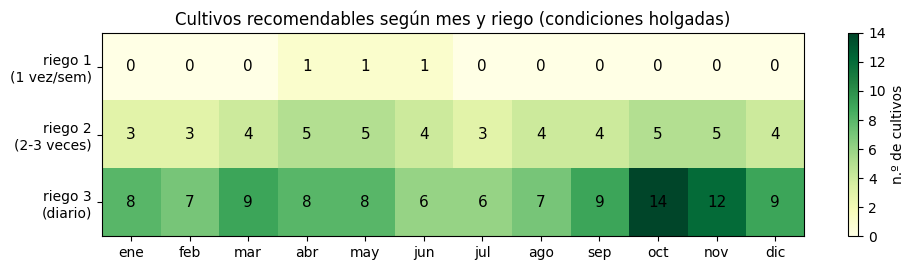

Con riego 2, cultivos vigentes por mes (ene → dic): [3, 3, 4, 5, 5, 4, 3, 4, 4, 5, 5, 4]


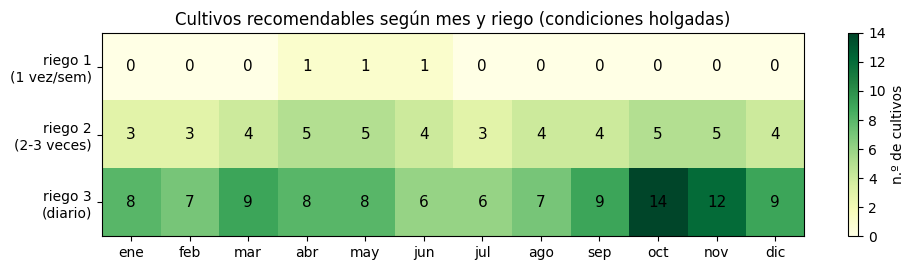

Con riego 2, cultivos vigentes por mes (ene → dic): [3, 3, 4, 5, 5, 4, 3, 4, 4, 5, 5, 4]


In [42]:
import matplotlib.pyplot as plt
import numpy as np

M = np.array([[len(oraculo(CATALOGO, 12, 10, 100, mes, cui)['rec']) for mes in range(1, 13)] for cui in (1, 2, 3)])

fig, ax = plt.subplots(figsize=(10, 2.8))
im = ax.imshow(M, cmap='YlGn', aspect='auto')
ax.set_xticks(range(12)); ax.set_xticklabels([m[:3] for m in MESES])
ax.set_yticks(range(3)); ax.set_yticklabels(['riego 1\n(1 vez/sem)', 'riego 2\n(2-3 veces)', 'riego 3\n(diario)'])
for i in range(3):
    for j in range(12):
        ax.text(j, i, M[i, j], ha='center', va='center', fontsize=11)
ax.set_title('Cultivos recomendables según mes y riego (condiciones holgadas)')
plt.colorbar(im, ax=ax, label='n.º de cultivos'); plt.tight_layout(); plt.show()

print("Con riego 2, cultivos vigentes por mes (ene → dic):", [int(x) for x in M[1]])

## 13. Huerta interactiva
Mové los controles y se vuelve a correr el motor. (Requiere `ipywidgets`; si no está, usá `mostrar(consultar(...))` directamente.)

In [43]:
try:
    import ipywidgets as w
    from IPython.display import clear_output

    s_luz  = w.FloatSlider(value=5.0, min=0.0, max=12.0, step=0.5, description='Horas de sol', style={'description_width': '110px'}, layout=w.Layout(width='480px'))
    s_esp  = w.FloatText(value=1.0, step=0.1, description='Espacio (m²)', style={'description_width': '110px'})
    s_prof = w.FloatText(value=30.0, step=1.0, description='Prof. (cm)', style={'description_width': '110px'})
    d_mes  = w.Dropdown(options=[(m.capitalize(), i + 1) for i, m in enumerate(MESES)], value=10, description='Mes', style={'description_width': '110px'})
    d_cui  = w.Dropdown(options=[(t, k) for k, t in OPCIONES_CUIDADO.items()], value=2, description='Riego', style={'description_width': '110px'}, layout=w.Layout(width='480px'))
    lbl    = w.Label()
    salida = w.Output()

    def _correr(*_):
        lbl.value = f"Etiqueta de luz (decorativa): {etiqueta_luz(s_luz.value)}"
        with salida:
            clear_output(wait=True)
            try:
                mostrar(consultar(s_luz.value, s_esp.value, s_prof.value, d_mes.value, d_cui.value))
            except ValueError as err:
                print("Entrada inválida:", err)

    for ctl in (s_luz, s_esp, s_prof, d_mes, d_cui):
        ctl.observe(_correr, names='value')
    display(w.VBox([s_luz, lbl, s_esp, s_prof, d_mes, d_cui, salida]))
    _correr()
except ImportError:
    print("ipywidgets no está instalado (pip install ipywidgets). Ejemplo manual:")
    mostrar(consultar(5.0, 1.0, 30, 10, 2))

## Interfaz UI Versión estable

In [44]:
import gradio as gr

# CSS para adaptar los contenedores al Modo Claro y Modo Oscuro de Gradio
css_adaptativo = """
/* --- MODO CLARO (Default) --- */
.contenedor-huerta {
    background-color: #f8f9fa;
    color: #1a1a1a;
    padding: 12px;
    border-radius: 6px;
    border-left: 4px solid #2e7d32;
    margin-bottom: 15px;
}
.tarjeta-recomendado {
    background-color: #f1f8e9;
    color: #1b5e20;
    border-left: 4px solid #4caf50;
    padding: 12px;
    border-radius: 6px;
    margin-bottom: 12px;
}
.tarjeta-recomendado h4 { color: #1b5e20 !important; margin: 0 0 5px 0; }
.texto-alerta { color: #d84315 !important; }
.texto-consejo { color: #e65100 !important; }
.lista-descartes { color: #b71c1c !important; }

/* --- MODO OSCURO (Google Colab / Gradio Dark) --- */
.dark .contenedor-huerta {
    background-color: #1e293b !important;
    color: #f8fafc !important;
    border-left: 4px solid #4ade80 !important;
}
.dark .tarjeta-recomendado {
    background-color: #064e3b !important;
    color: #ecfdf5 !important;
    border-left: 4px solid #34d399 !important;
}
.dark .tarjeta-recomendado h4 { color: #a7f3d0 !important; }
.dark .texto-alerta { color: #fca5a5 !important; }
.dark .texto-consejo { color: #fde047 !important; }
.dark .lista-descartes { color: #fca5a5 !important; }
"""

def evaluar_huerta_adaptativa(horas_sol, espacio_m2, profundidad_cm, mes_nombre, frecuencia_ui):
    try:
        d_mes = MESES.index(mes_nombre.lower()) + 1
        d_cui = [k for k, v in OPCIONES_CUIDADO.items() if v == frecuencia_ui][0]

        res = consultar(
            horas_sol=float(horas_sol),
            espacio_m2=float(espacio_m2),
            profundidad_cm=float(profundidad_cm),
            mes=d_mes,
            cuidado=d_cui
        )

        p = res.perfil
        html = f"""
        <div class="contenedor-huerta">
            <b>Huerta:</b> {fmt(p['horas_sol'])} h de sol ({etiqueta_luz(p['horas_sol'])}) · {fmt(p['espacio_m2'])} m² ·
            recipiente de {fmt(p['profundidad_cm'])} cm · {MESES[p['mes'] - 1].capitalize()} ({p['estacion']})<br>
            <b>Riego:</b> «{OPCIONES_CUIDADO[p['cuidado']]}»
        </div>
        """

        if res.sin_resultados:
            html += f"<div class='tarjeta-recomendado' style='border-color:#ef4444;'>🚫 {res.mensaje_sin_resultados}</div>"
        else:
            html += f"<h3>✅ CULTIVOS RECOMENDADOS ({len(res.recomendados)})</h3>"
            for nombre, r in res.recomendados.items():
                html += f"""
                <div class="tarjeta-recomendado">
                    <h4>🌿 {nombre}</h4>
                    <p><b>Por qué:</b> {' · '.join(t for _, t in r['justificacion'])}</p>
                    <p><b>Riego:</b> {r['pautas']['riego']}</p>
                    <p><b>Mantenimiento:</b> {r['pautas']['mantenimiento']}</p>
                    <p><b>Cosecha:</b> {r['pautas']['cosecha']}</p>
                    <p><b>Cómo empezar:</b> {r['inicio']}</p>
                """
                for c in r['consejos']:
                    html += f"<p class='texto-consejo'>💡 {c}</p>"
                for a in r['advertencias']:
                    html += f"<p class='texto-alerta'>⚠️ {a}</p>"
                html += "</div>"

        if res.descartes:
            html += f"<h4>❌ DESCARTADOS ({len(res.descartes)}) — motivo:</h4><ul class='lista-descartes'>"
            for nombre, motivos in res.descartes.items():
                for motivo, texto in motivos:
                    html += f"<li>{ICONO[motivo]} <b>{nombre}</b> [{motivo}]: {texto}</li>"
            html += "</ul>"

        html += f"<p style='font-size:11px; opacity:0.8;'>ℹ️ {AVISO_FIJO}</p>"
        return html

    except Exception as err:
        return f"<div style='color:red;'>⚠️ Entrada inválida: {err}</div>"

# Crear la app pasando el parámetro css
with gr.Blocks(title="Sistema Experto Huertas AMBA", css=css_adaptativo) as demo:
    gr.Markdown("## 🌱 Sistema Experto de Selección de Cultivos Urbanos (AMBA)")

    with gr.Row():
        with gr.Column(scale=1):
            s_luz = gr.Slider(0.0, 12.0, value=5.0, step=0.5, label="Horas de sol")
            s_esp = gr.Number(value=1.0, label="Espacio (m²)", precision=2)
            s_prof = gr.Number(value=30.0, label="Profundidad (cm)", precision=1)
            d_mes = gr.Dropdown([m.capitalize() for m in MESES], value="Octubre", label="Mes")
            d_cui = gr.Dropdown(list(OPCIONES_CUIDADO.values()), value=OPCIONES_CUIDADO[2], label="Riego")

        with gr.Column(scale=2):
            salida_html = gr.HTML()

    inputs = [s_luz, s_esp, s_prof, d_mes, d_cui]
    for ctl in inputs:
        ctl.change(fn=evaluar_huerta_adaptativa, inputs=inputs, outputs=salida_html)

    demo.load(fn=evaluar_huerta_adaptativa, inputs=inputs, outputs=salida_html)

demo.launch(inline=True)

/tmp/ipykernel_20202/1097061434.py:100: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Sistema Experto Huertas AMBA", css=css_adaptativo) as demo:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://705376a5b1812f7583.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/tmp/ipykernel_20202/1097061434.py:100: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Sistema Experto Huertas AMBA", css=css_adaptativo) as demo:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6335e266c4962c9344.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [45]:
!pip install streamlit
!npm install -q -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧
changed 22 packages in 2s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧Requirement already satisfied: streamlit in /usr/local/lib/python3.13/dist-packages (1.66.1)
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙
changed 22 packages in 2s
⠙
⠙3 packages are looking for funding
⠙  run `npm fund` for details
⠙

In [46]:
%%writefile app.py
import streamlit as st
import pandas as pd
# IMPORTANTE: Aquí van las importaciones de tu motor Experta y la carga del CSV
# from tu_script import consultar, CATALOGO, MESES, OPCIONES_CUIDADO, ...

st.set_page_config(page_title="Sistema Experto Huerta AMBA", page_icon="🌱", layout="wide")

st.title("🌱 Sistema Experto de Selección de Cultivos Urbanos (AMBA)")
st.caption("Basado en normas agroecológicas del INTA ProHuerta")

st.sidebar.header("⚙️ Parámetros de tu Huerta")

s_luz = st.sidebar.slider("Horas de sol directo", 0.0, 12.0, 5.0, 0.5)
st.sidebar.info(f"Luz decorativa: **{etiqueta_luz(s_luz)}**")

s_esp = st.sidebar.number_input("Espacio disponible (m²)", min_value=0.01, value=1.0, step=0.1)
s_prof = st.sidebar.number_input("Profundidad del recipiente (cm)", min_value=1.0, value=30.0, step=1.0)

mes_nombre = st.sidebar.selectbox("Mes de evaluación", [m.capitalize() for m in MESES], index=9)
d_mes = MESES.index(mes_nombre.lower()) + 1

d_cui_label = st.sidebar.selectbox("Frecuencia de riego", list(OPCIONES_CUIDADO.values()), index=1)
d_cui = [k for k, v in OPCIONES_CUIDADO.items() if v == d_cui_label][0]

# Ejecutar el motor
res = consultar(s_luz, s_esp, s_prof, d_mes, d_cui)

# Renderizar en pantalla completa
# (Misma estructura de st.expander y st.write)


Overwriting app.py
Overwriting app.py


In [47]:
!wget -qO- ://icanhazip.com
!streamlit run app.py & npx localtunnel --port 8501

⠙

⠹⠸⠼⠴⠦⠧⠇⠏your url is: https://wise-hats-roll.loca.lt
2026-10-24 04:34:23.441 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.91.176.111:8501

────────────────────────── Traceback (most recent call last) ───────────────────────────
  /usr/local/lib/python3.13/dist-packages/streamlit/runtime/scriptrunner/exec_code.py:  
  136 in exec_func_with_error_handling                                                  
                                                                                        
  /usr/local/lib/python3.13/dist-packages/streamlit/runtime/scriptrunner/script_runner  
  .py:924 in code_to_exec                                                               
                                                                                        
  /content/app.py:14 in <module>                                                        
 

In [ ]:
EMOJIS_CULTIVOS = {
    "Acelga": "🥬",
    "Albahaca": "🌿",
    "Apio": "🥬",
    "Calabaza": "🎃",
    "Espinaca": "🥬",
    "Haba": "🫘",
    "Lechuga": "🥬",
    "Maíz dulce": "🌽",
    "Melón": "🍈",
    "Pepino": "🥒",
    "Perejil": "🌿",
    "Rabanito": "🌱",
    "Rúcula": "🥬",
    "Tomate": "🍅",
    "Zanahoria": "🥕",
    "Zapallito": "🥒"
}